# Bài tập Buổi 1 - Phần B
**Nhóm 01** | Xây dựng bộ công cụ nâng cao chất lượng ảnh

Notebook chạy bằng cách import các hàm trong `pipeline.py`. Giữ file này cùng thư mục notebook.

In [1]:
from pipeline import (create_data, verify_b1, run_b2, run_b3, run_b4, report, OUT)
from IPython.display import display, Image
records, reference, degraded = create_data()
print("Loaded", len(records), "sample images")

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded 6 sample images


## B1 - Tự cài đặt và kiểm chứng
Các hàm NumPy `hist_equalize`, `conv2d`, `median_filter`, `laplacian_sharpen` nằm trong `pipeline.py`; bảng MAE và thời gian trong `results/B1_comparison.csv`.

In [2]:
b1 = verify_b1(reference)

B1 | Algorithm | MAE | NumPy ms | OpenCV ms
hist_equalize | 0.000000 | 1.08 | 0.33
conv2d_5x5 | 0.000000 | 32.81 | 0.57
median_filter_5 | 0.000000 | 67.45 | 0.38
laplacian_sharpen_c1 | 0.000000 | 4.46 | 0.62


## B2 - Thử nghiệm tham số và PSNR/SSIM
Đối chiếu ảnh biến đổi với ảnh tham chiếu ban đầu; các đồ thị và bảng sẽ được lưu trong `results/`.

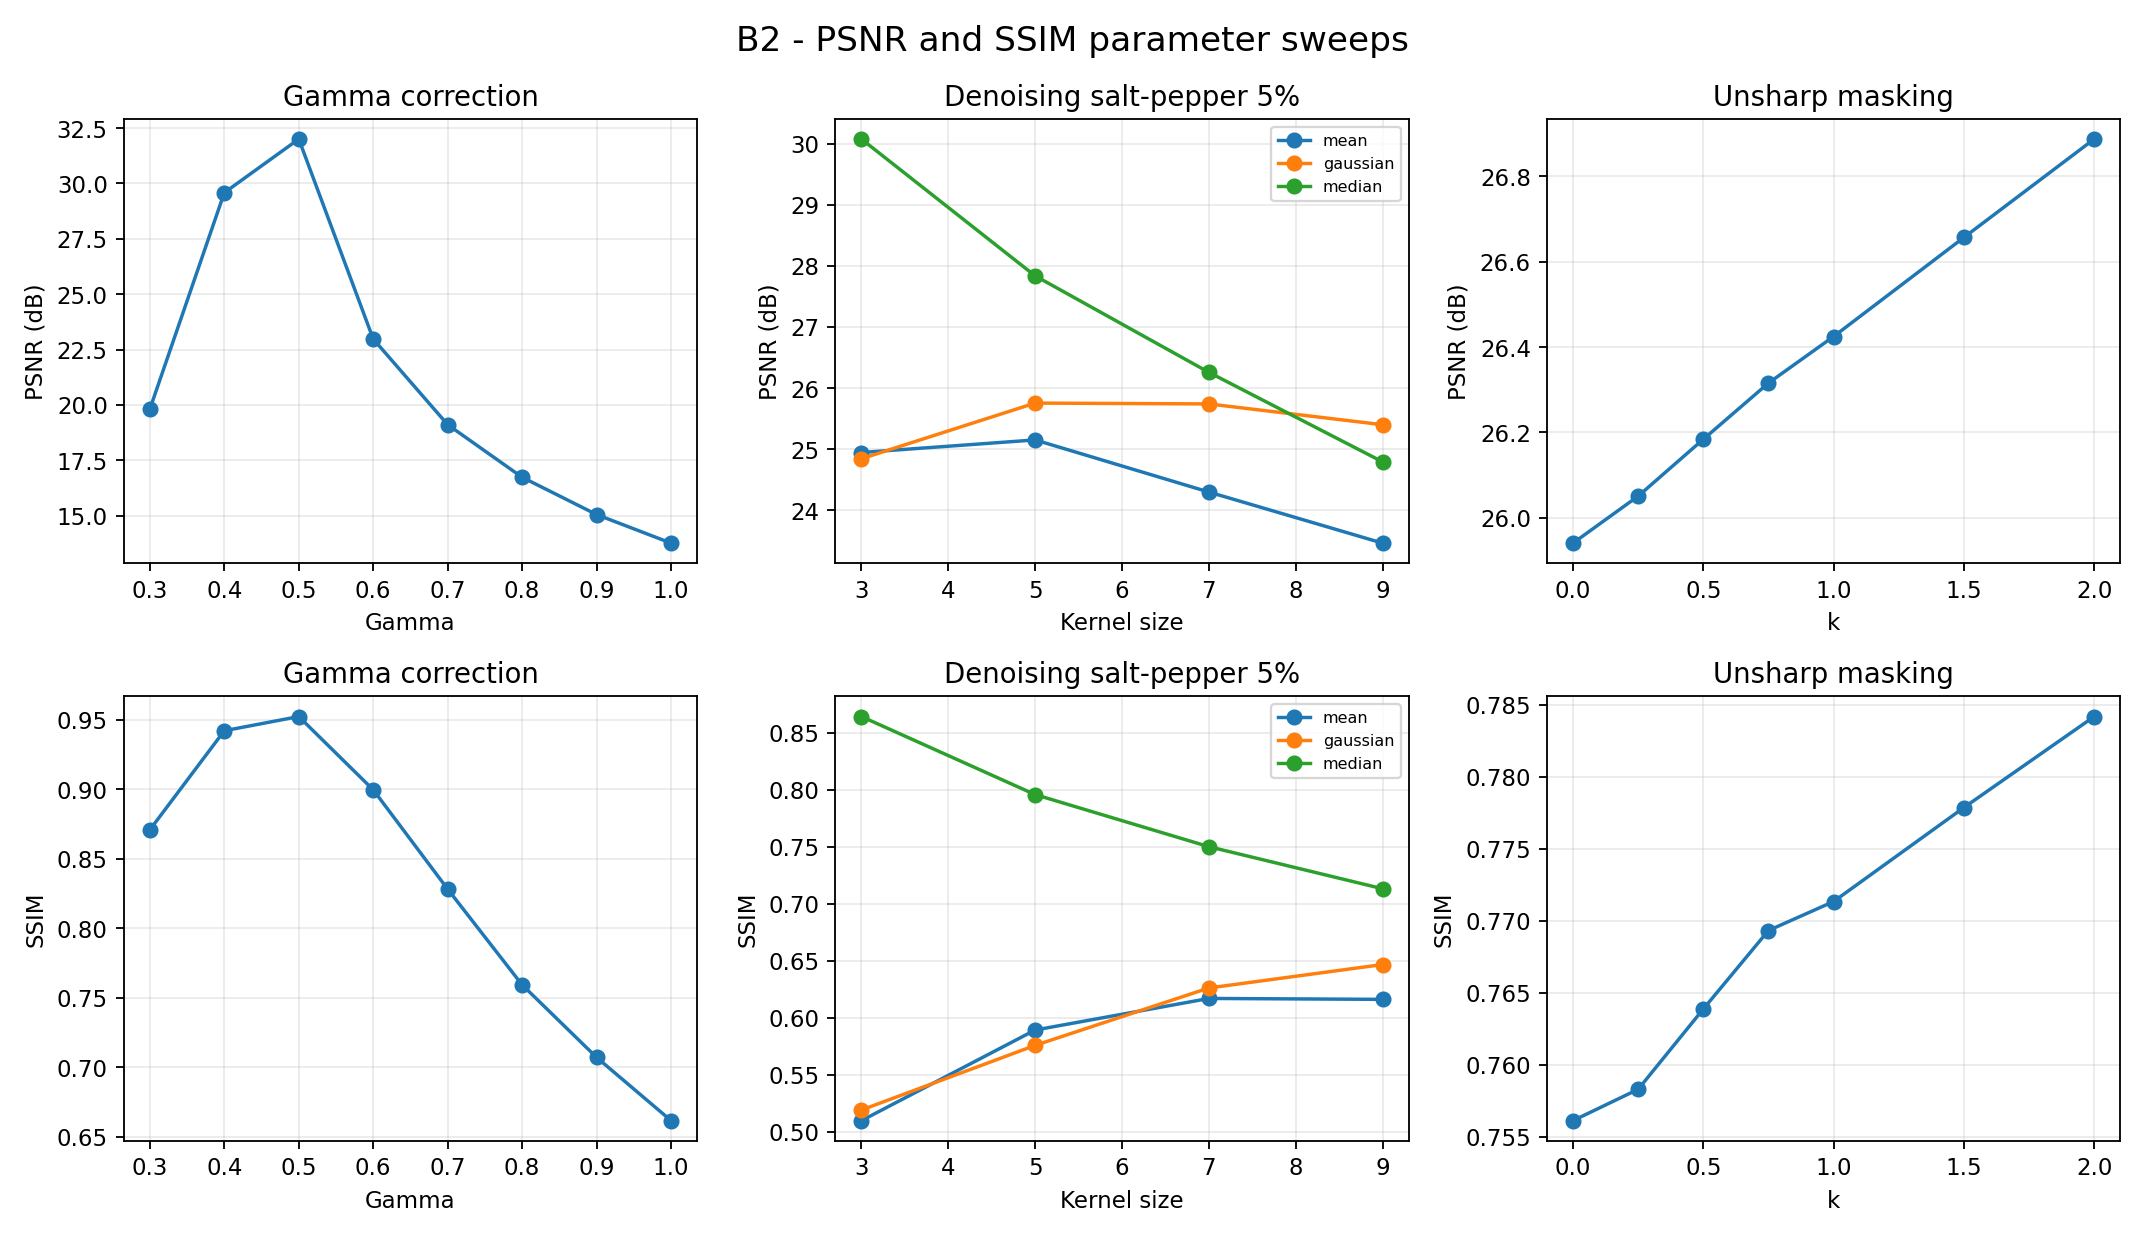

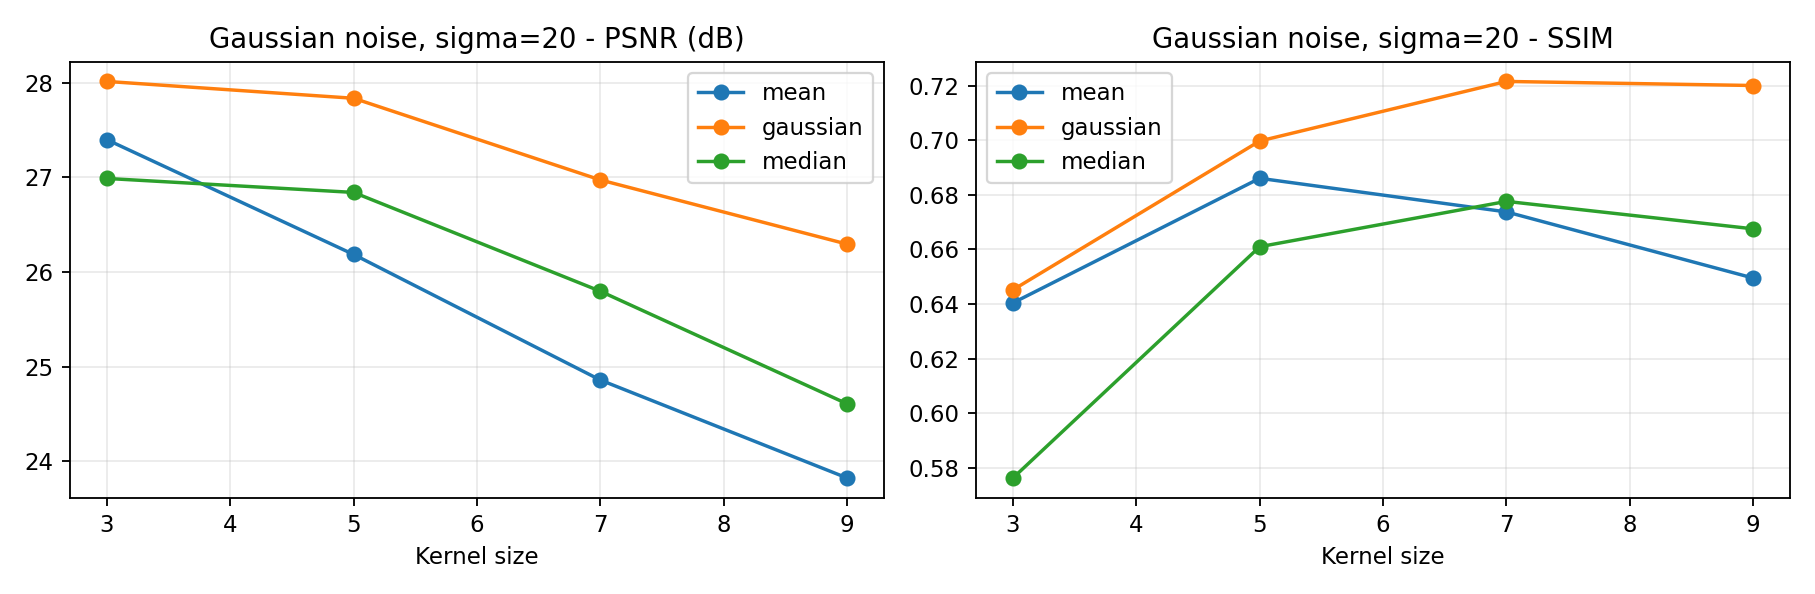

In [3]:
b2 = run_b2(reference, degraded)
display(Image(filename=str(OUT / "B2_metrics_plot.png")))
display(Image(filename=str(OUT / "B2_gaussian_noise_plot.png")))

## B3 - Pipeline ba bước
Median 3×3 → CLAHE clipLimit=1.6 → Unsharp k=0.5; kết quả được kiểm chứng với ảnh gốc cho từng ảnh.

('lowlight_camera', 'lowlight', 13.757, 15.467, 0.6615, 0.6618)
('lowlight_coins', 'lowlight', 13.084, 15.471, 0.5464, 0.6033)
('noise_moon', 'noise', 18.96, 26.577, 0.1891, 0.879)
('noise_clock', 'noise', 22.128, 20.296, 0.1535, 0.1431)
('blur_page', 'blur', 19.102, 18.352, 0.6071, 0.6465)
('blur_coffee', 'blur', 26.914, 20.837, 0.7827, 0.7653)


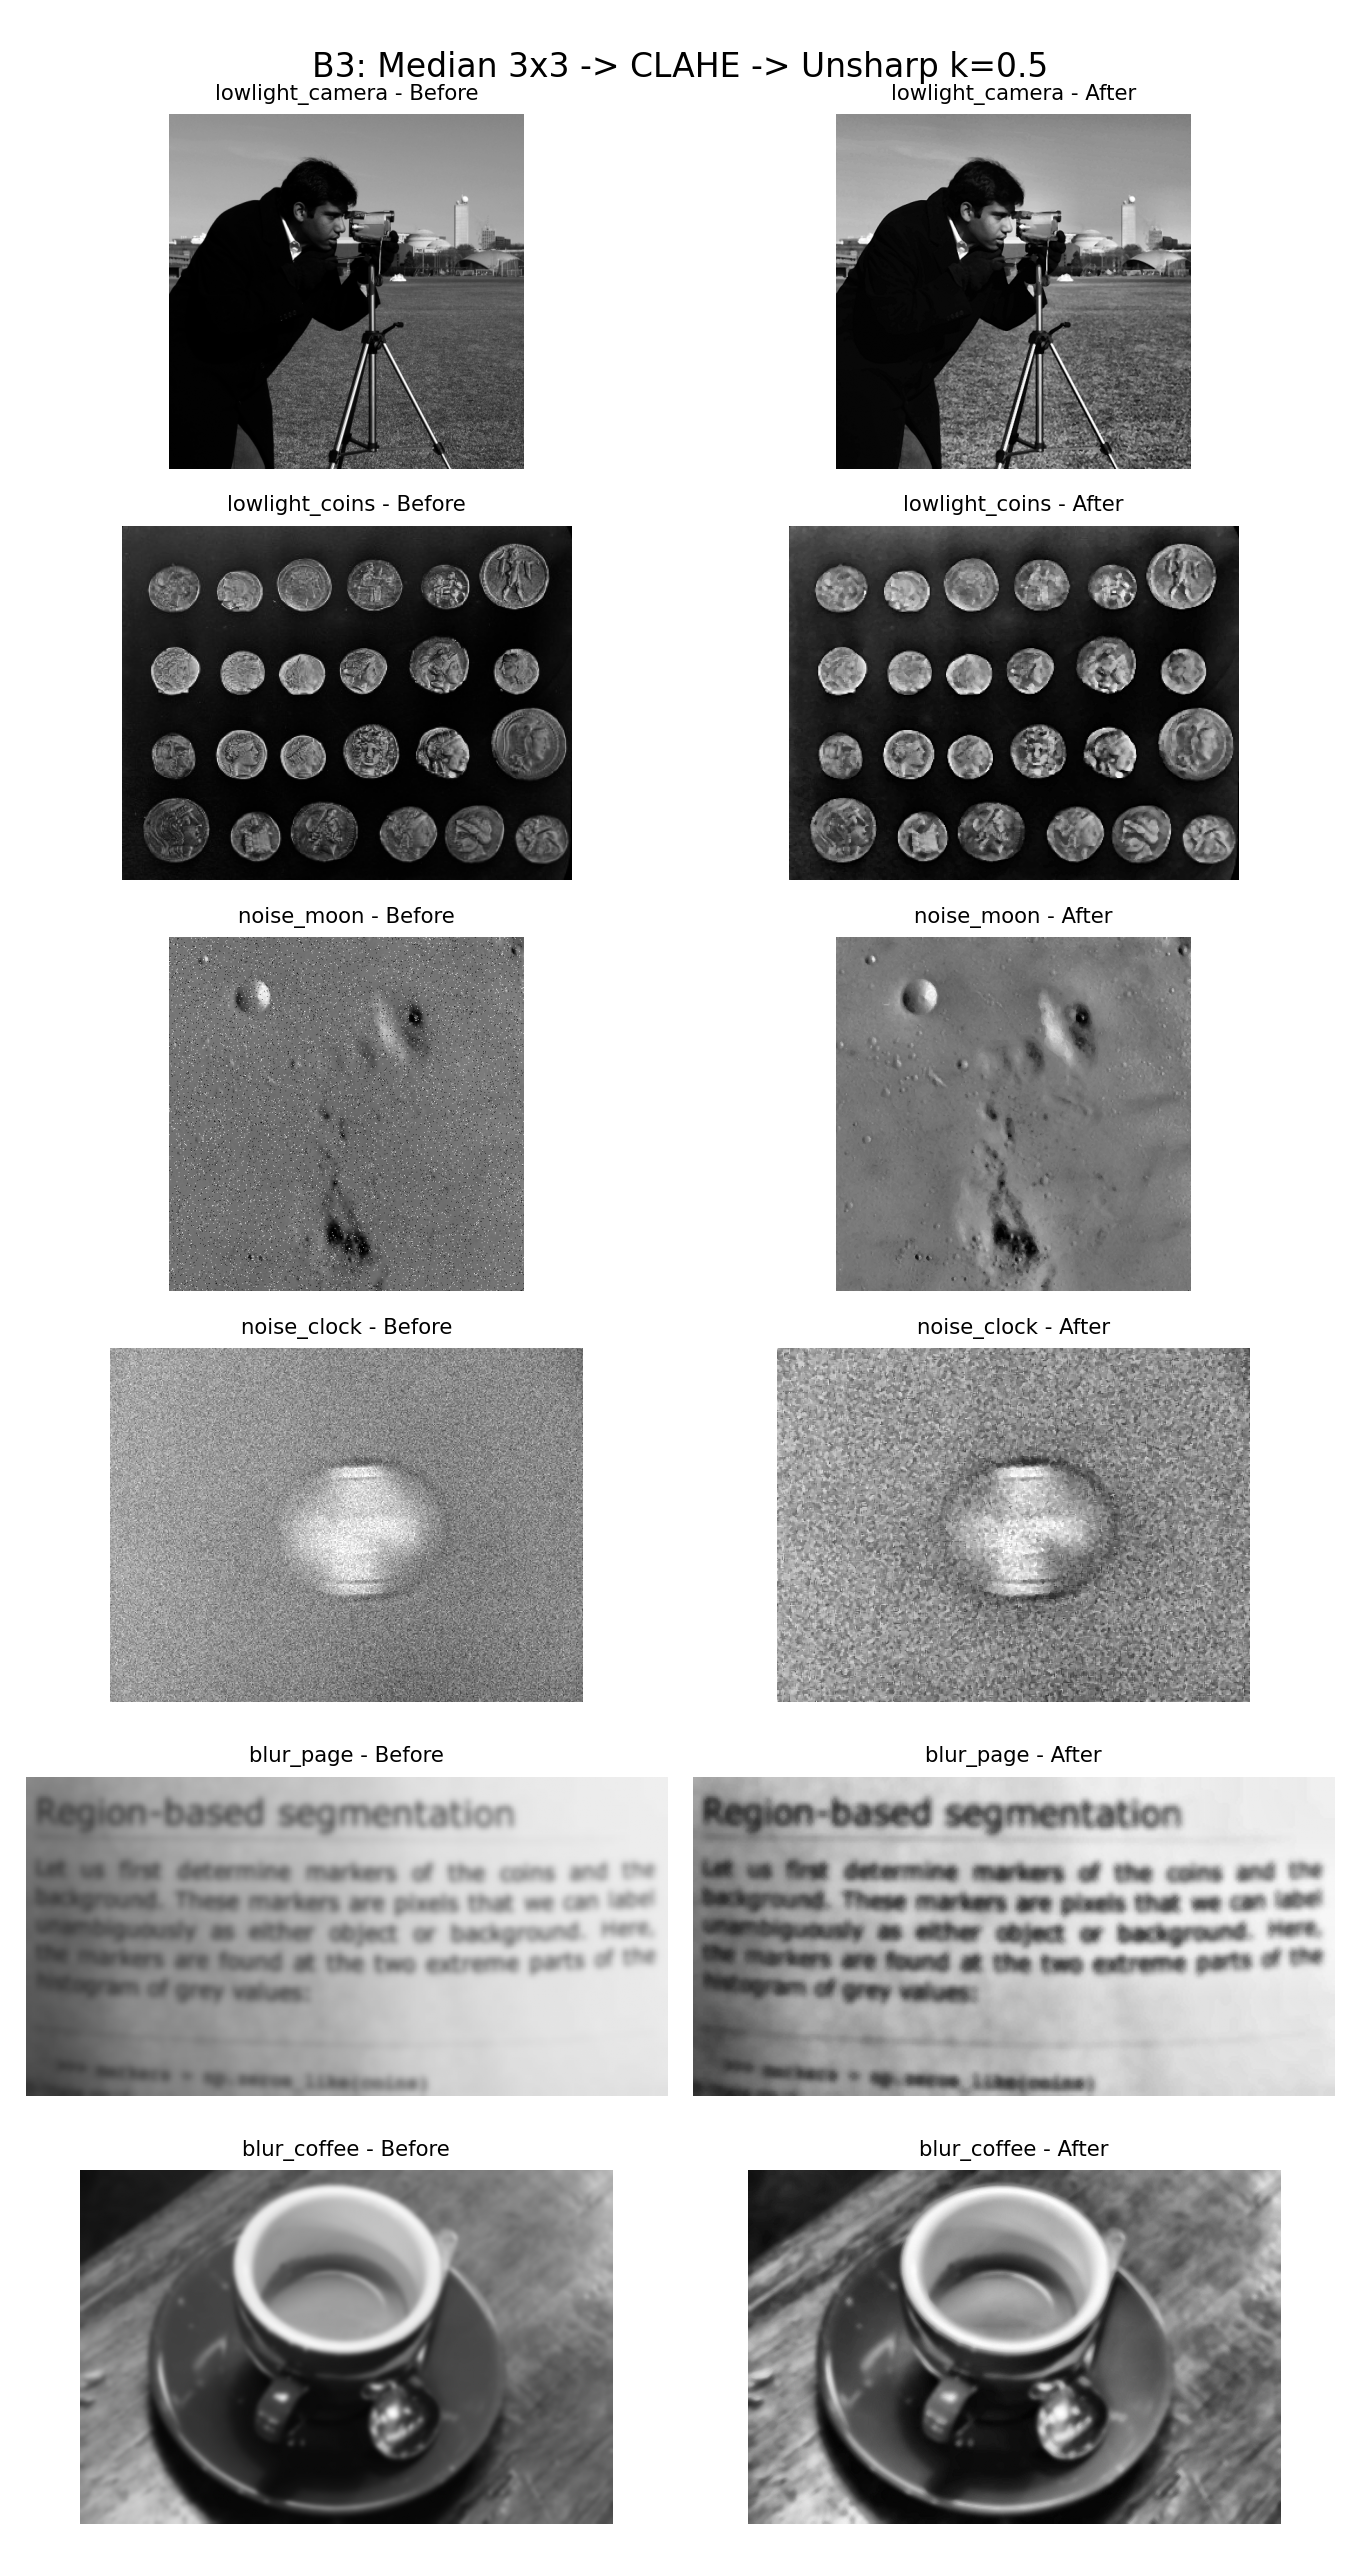

In [4]:
b3 = run_b3(records)
for row in b3: print(row)
display(Image(filename=str(OUT / "B3_six_before_after.png")))

## B4 - Hai trường hợp thất bại
CLAHE quá mạnh và unsharp hệ số lớn có thể khuếch đại nhiễu / tạo quầng.

Strong CLAHE can exaggerate noise; lower clipLimit or denoise first.
Strong unsharp masking can create overshoot/ringing; reduce k or use edge-aware sharpening.


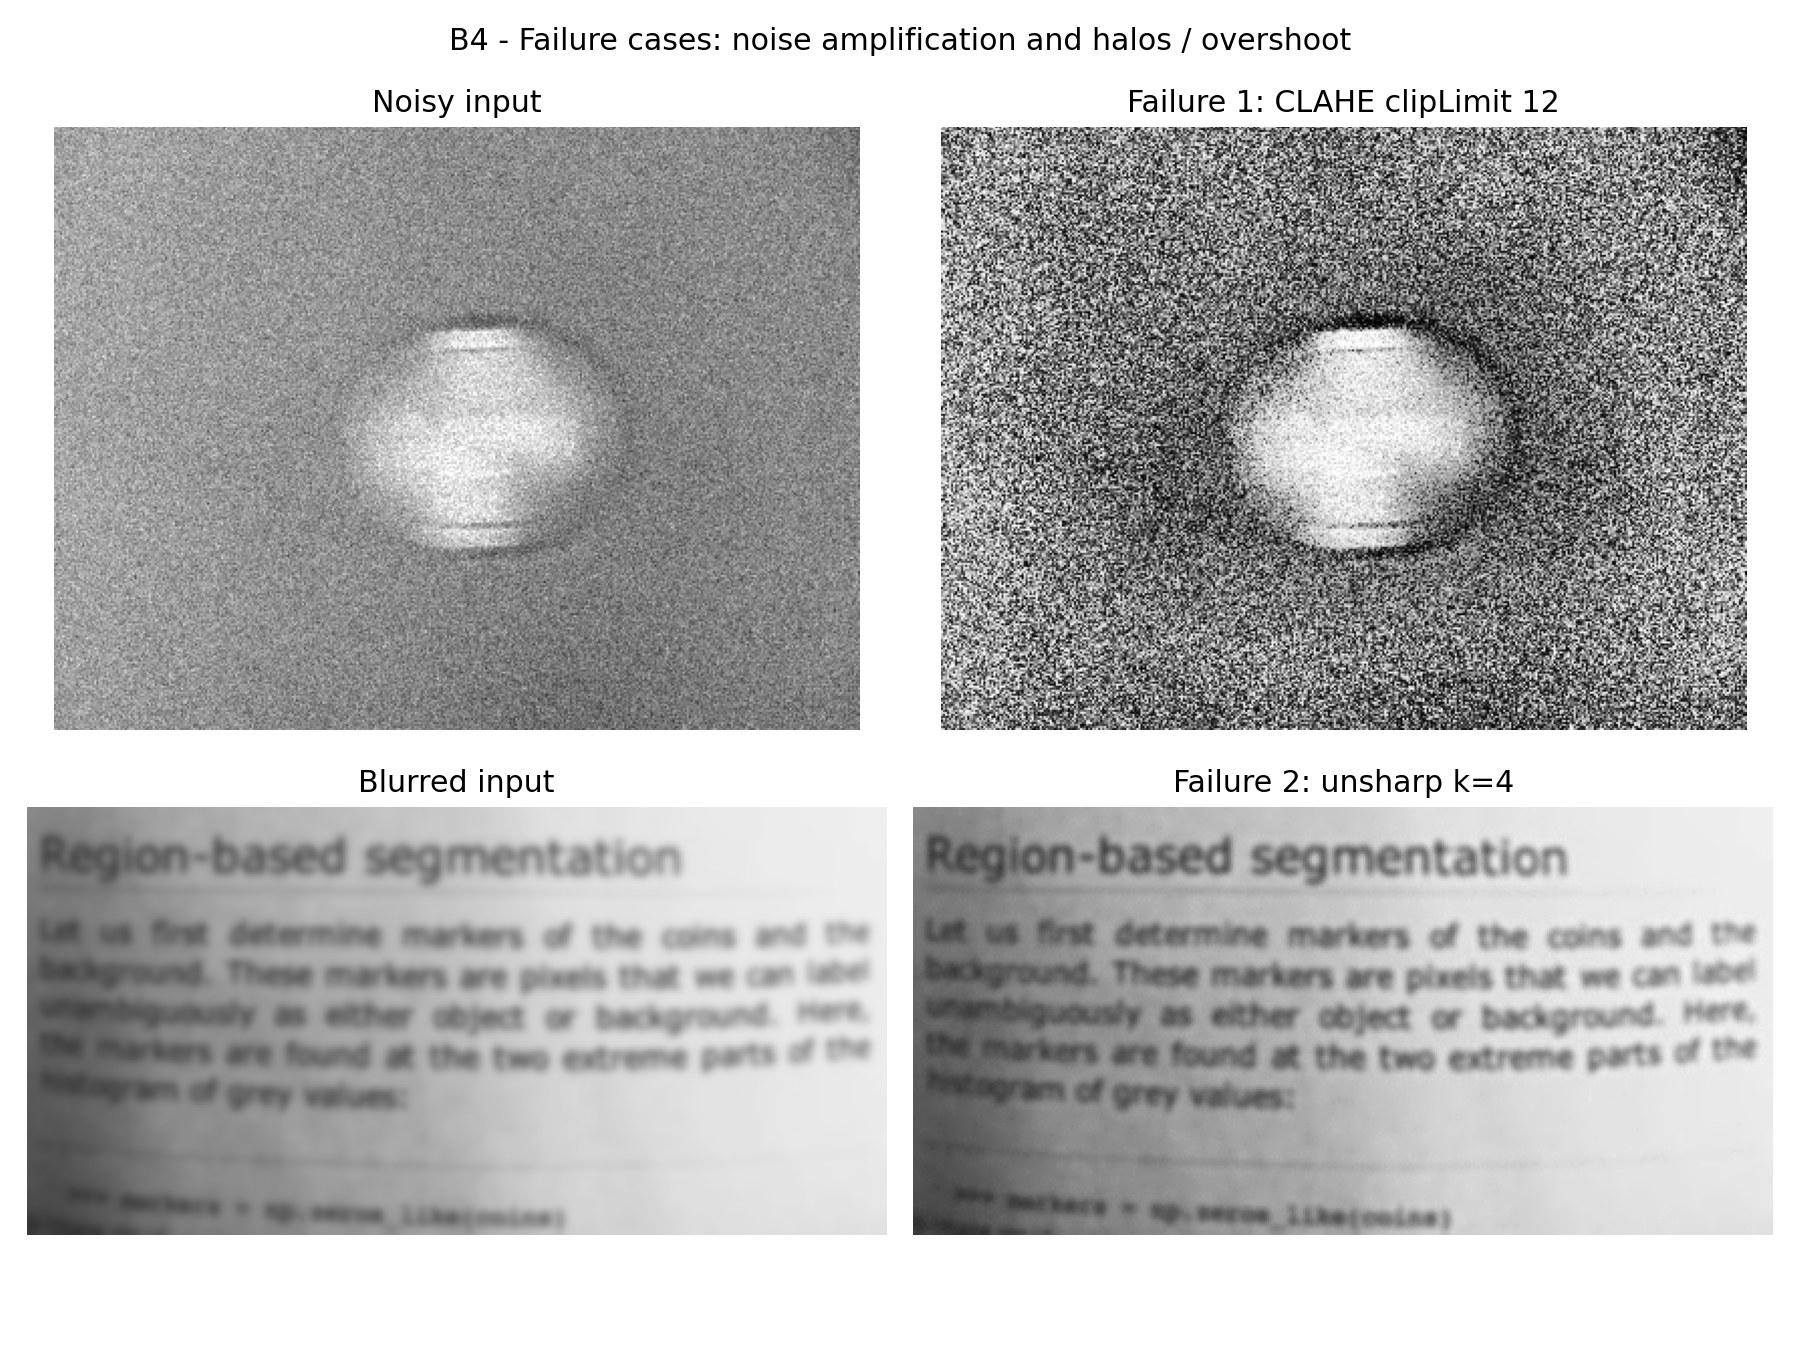

In [5]:
b4 = run_b4(records)
for remark in b4: print(remark)
display(Image(filename=str(OUT / "B4_failure_cases.png")))

## B5 - Đạo đức, xuất báo cáo
Báo cáo chứa nguồn mẫu, quyền sử dụng cần xác minh, cảnh báo chỉnh sửa làm sai lệch thông tin. **Bắt buộc** thay nhóm 01 và điền thông tin, phân công thực tế.

In [6]:
pdf_path = report(reference,b1,b2,b3,b4)
print("Created:",pdf_path)

Wrote: /mnt/data/B1_NhomXX_Project/BaoCao_B1_NhomXX.pdf
Created: /mnt/data/B1_NhomXX_Project/BaoCao_B1_NhomXX.pdf
